# Treatment units, one at a time: how each works and how it is checked

One section per conventional-treatment unit: `Sedimentation`, `Filtration`, `Disinfection`, `GACAdsorber`. Each shows what the unit does, then the check behind it. The train as a whole, with a design problem, is notebook 74.

| Unit | Checked against |
|---|---|
| `Sedimentation` | the ideal-basin result, re-derived by tracking particles (no published data set) |
| `Filtration` | the removal law re-derived slice by slice; Yao's efficiency as restated by Messina et al. (2015); no published filter data |
| `Disinfection` | the US EPA's CT table for 3-log *Giardia* inactivation by free chlorine (Surface Water Treatment Rule guidance, 1991) |
| `GACAdsorber` | WaterTAP 1.8.0 (an implementation check; Hand et al. 1984 not read) |

In [1]:
import json
from pathlib import Path
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from difflow import make_stream

import difflow_water as dw
from difflow_water.treatment import collector_efficiency, stokes_velocity

ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
BENCH = ROOT / "benchmarks"
water = lambda **solids: make_stream({"H2O": 5.55e4, **solids}, T=288.15, P=101325.0)   # about 1 m3/s

## 1. `Sedimentation`: the ideal basin

Hazen's (1904) and Camp's (1946) ideal basin: plug flow, discrete particles settling at their own velocity. A particle class is removed in the fraction `min(1, v_s / v_o)` with `v_o = Q / A` the overflow rate: removal depends on the surface area, not the depth. Settling velocities come from Stokes' law.

area   500 m2: overflow  7.20 m/h, removal fine/coarse [0.001 0.12 ]
area  1000 m2: overflow  3.60 m/h, removal fine/coarse [0.002 0.239]
area  2000 m2: overflow  1.80 m/h, removal fine/coarse [0.005 0.479]
area  4000 m2: overflow  0.90 m/h, removal fine/coarse [0.01  0.958]


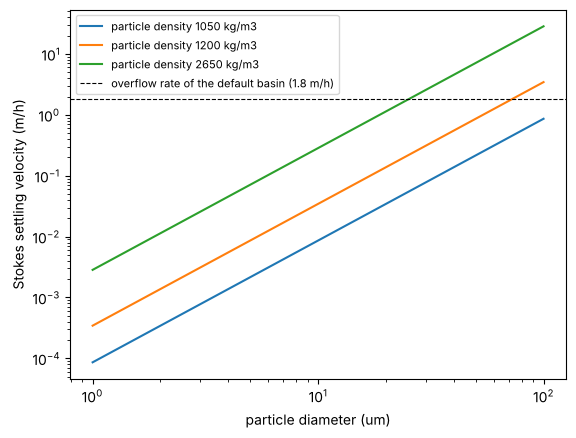

In [2]:
d = np.logspace(-6, -4, 60)
for rho_p in (1050.0, 1200.0, 2650.0):
    v = np.asarray(stokes_velocity(d, rho_p, 288.15))
    plt.loglog(d * 1e6, v * 3600, label=f"particle density {rho_p:.0f} kg/m3")
plt.axhline(1.8, color="k", ls="--", lw=0.8, label="overflow rate of the default basin (1.8 m/h)")
plt.xlabel("particle diameter (um)"); plt.ylabel("Stokes settling velocity (m/h)"); plt.legend(fontsize=8)
areas = [500.0, 1000.0, 2000.0, 4000.0]
for A in areas:
    _, _, i = dw.Sedimentation(dw.SedimentationParams(area=A))(water(TSS_fine=20.0, TSS_coarse=30.0))
    print(f"area {A:5.0f} m2: overflow {float(i['overflow_rate']) * 3600:5.2f} m/h, removal fine/coarse {np.round(np.asarray(i['removal']), 3)}")

**Check: the removal law, re-derived by tracking particles.** Particles enter a rectangular basin (length `L`, width `W`, depth `H`) at heights spread evenly over the depth, move with the water at `u = Q / (W H)` and fall at `v_s`; a particle is removed if it reaches the floor before the outlet. The fraction removed, counted over 20,000 entry heights, is compared with the unit's `min(1, v_s / v_o)` at three depths (Stokes' law itself holds only while the particle Reynolds number is below about 1, which the cell also reports).

In [3]:
Q, L, W = 1.0, 100.0, 20.0
mu = 1.138e-3
for vs in (1e-4, 4e-4, 8e-4):
    rows = []
    for H in (2.0, 4.0, 8.0):
        h0 = (np.arange(20000) + 0.5) / 20000 * H
        u = Q / (W * H)
        removed = np.mean(h0 / vs <= L / u)
        rows.append(removed)
    unit = float(dw.Sedimentation(dw.SedimentationParams(area=L * W, settling_velocity=(vs, vs)))(water(TSS_fine=1.0, TSS_coarse=1.0))[2]["removal"][0])
    d_eq = np.sqrt(18 * mu * vs / ((1050 - 1000) * 9.80665))
    Re = 1000 * vs * d_eq / mu
    print(f"v_s {vs * 3600:4.2f} m/h: tracked removal at H = 2, 4, 8 m {np.round(rows, 4)}; unit {unit:.4f}; "
          f"Stokes diameter at 1050 kg/m3 {d_eq * 1e6:5.1f} um (Re {Re:.1e})")

v_s 0.36 m/h: tracked removal at H = 2, 4, 8 m [0.2 0.2 0.2]; unit 0.2000; Stokes diameter at 1050 kg/m3  64.6 um (Re 5.7e-03)
v_s 1.44 m/h: tracked removal at H = 2, 4, 8 m [0.8 0.8 0.8]; unit 0.8001; Stokes diameter at 1050 kg/m3 129.3 um (Re 4.5e-02)
v_s 2.88 m/h: tracked removal at H = 2, 4, 8 m [1. 1. 1.]; unit 1.0000; Stokes diameter at 1050 kg/m3 182.8 um (Re 1.3e-01)


The tracked fraction equals the unit's at every depth (to the 1/20,000 counting resolution): the removal law is the ideal basin's. No published settling-column or basin data set was reachable; flocculent and hindered settling (Camp's types II and III) are outside this model.

## 2. `Filtration`: clean-bed depth filtration

Each media grain is a collector: Yao, Habibian & O'Melia (1971) add three transport mechanisms into the single-collector efficiency (diffusion, gravity, interception), here in the form Messina, Marchisio & Sethi (2015) restate (read). The famous consequence is a particle size that filters worst, around 1 um: too big to diffuse, too small to settle or be intercepted.

least-removed particle 1.63 um at 12 m/h through 0.5 mm sand


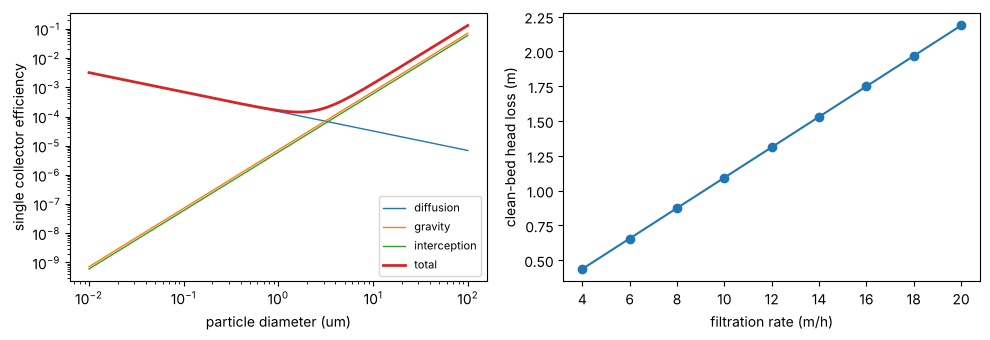

In [4]:
U = 12.0 / 3600
dps = np.logspace(-8, -4, 200)
ce = collector_efficiency(dps, 1050.0, 0.5e-3, U, 288.15)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for k, lab in [("eta_D", "diffusion"), ("eta_G", "gravity"), ("eta_I", "interception"), ("eta", "total")]:
    ax[0].loglog(dps * 1e6, np.asarray(ce[k]), label=lab, lw=2 if k == "eta" else 1)
ax[0].set_xlabel("particle diameter (um)"); ax[0].set_ylabel("single collector efficiency"); ax[0].legend(fontsize=8)
i_min = int(np.argmin(np.asarray(ce["eta"])))
print(f"least-removed particle {dps[i_min] * 1e6:.2f} um at 12 m/h through 0.5 mm sand")
rates = np.linspace(4, 20, 9)
hl = [float(dw.Filtration(dw.FiltrationParams(area=1.0 / (r / 3600)))(water(TSS_fine=1.0, TSS_coarse=1.0))[2]["head_loss"]) for r in rates]
ax[1].plot(rates, hl, "o-"); ax[1].set_xlabel("filtration rate (m/h)"); ax[1].set_ylabel("clean-bed head loss (m)")
fig.tight_layout()

**Checks.**

- *The removal law, re-derived.* The unit's `ln(C/C0) = -(3/2)(1 - eps) alpha eta L / d_c` follows from counting collectors in a slice of bed. Integrating that slice balance numerically, layer by layer, must give the same outlet concentration.
- *Yao's efficiency* is the one Messina et al. (2015, Eq. 1 and Table 1) state; that paper also notes Yao's form can exceed 1 at the extremes, which this cell reports.
- *Carman-Kozeny* is linear in the filtration rate (laminar flow through the grains); the grain Reynolds number shows where that holds.

No published filter-run data set (effluent turbidity, head loss over a run) was reachable.

In [5]:
p = dw.FiltrationParams()
filt, _, info = dw.Filtration(p)(water(TSS_fine=2.0, TSS_coarse=0.5))
eps, a, dc, Lb = p.porosity, p.alpha, p.media_diameter, p.depth
for j, name in enumerate(["TSS_fine", "TSS_coarse"]):
    eta = float(info["eta"][j]); C = 1.0; n = 20000; dz = Lb / n
    collectors_per_m3 = (1 - eps) / (np.pi * dc**3 / 6)
    for _ in range(n):   # each collector sweeps alpha*eta of its projected area's flux
        C -= collectors_per_m3 * a * eta * (np.pi * dc**2 / 4) * C * dz
    print(f"{name}: slice-by-slice {C:.6f}, unit {1 - float(info['removal'][j]):.6f}")
print("largest Yao efficiency over 0.01-100 um:", f"{float(np.max(np.asarray(ce['eta']))):.2f}",
      "(above 1 means the correlation has left its range)")
Re = 1000 * (12 / 3600) * dc / 1.138e-3
print(f"grain Reynolds number at 12 m/h: {Re:.2f} (Carman-Kozeny assumes laminar, Re below about 1-10)")

TSS_fine: slice-by-slice 0.414314, unit 0.414322
TSS_coarse: slice-by-slice 0.000000, unit 0.000000
largest Yao efficiency over 0.01-100 um: 0.13 (above 1 means the correlation has left its range)
grain Reynolds number at 12 m/h: 1.46 (Carman-Kozeny assumes laminar, Re below about 1-10)


## 3. `Disinfection`: Chick-Watson against the EPA CT table

The unit inactivates organisms by `dN/dt = -k C^n N` (Chick 1908, Watson 1908) in tanks in series, with the chlorine residual decaying. In plug flow without decay, 3-log inactivation requires `k C^n t = 3 ln 10`, i.e. a concentration-time product

`CT_3log = 3 ln 10 / k * C^(1 - n)`.

The US EPA's Surface Water Treatment Rule guidance (1991) tabulates exactly this: CT for 3-log *Giardia* inactivation by free chlorine, against residual, temperature and pH. The values below are its 5 C and 15 C columns at pH 7.0, residuals 0.6-2.8 mg/L, as reproduced in Table 1 of the Tennessee Department of Environment and Conservation's *Guidance Manual for Determination of Disinfectant Contact Time and CT Requirements* (1991) (the open copy read here; the rows "< 0.4" and "> 3.0" are bounds and are left out).

Chick-Watson has two constants per temperature and pH. Fitting them to each column tests whether the kinetic form describes the regulatory data (the residual), and the unit, run near plug flow at the table's CT, should then deliver 3 logs.

In [6]:
C_tab = np.array([0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4, 2.6, 2.8])
CT_tab = {5.0: np.array([143, 146, 149, 152, 155, 158, 162, 165, 169, 172, 175, 178.0]),
          15.0: np.array([72, 73, 75, 76, 78, 79, 81, 83, 85, 86, 88, 89.0])}
fits = {}
for T, CT in CT_tab.items():
    slope, icpt = np.polyfit(np.log(C_tab), np.log(CT), 1)       # ln CT = ln(3 ln10 / k) + (1 - n) ln C
    n = 1 - slope; k = 3 * np.log(10) / np.exp(icpt)
    resid = np.exp(icpt + slope * np.log(C_tab)) / CT - 1
    fits[T] = (k, n)
    print(f"{T:4.0f} C, pH 7: k = {k:.4f} (L/mg)^n/min, n = {n:.3f}; fit within {np.max(np.abs(resid)) * 100:.1f} % of every tabulated CT")

   5 C, pH 7: k = 0.0460 (L/mg)^n/min, n = 0.854; fit within 2.6 % of every tabulated CT
  15 C, pH 7: k = 0.0917 (L/mg)^n/min, n = 0.855; fit within 2.8 % of every tabulated CT


In [7]:
print("            table CT   contact   plug flow, fitted law   unit, 200 tanks in series (no decay)")
for T, CT in CT_tab.items():
    k, n = fits[T]
    for C, ct in zip(C_tab[::3], CT[::3]):
        V = ct / C * 60.0 * 1.0   # m3 at 1 m3/s
        _, info = dw.Disinfection(dw.DisinfectionParams(k=k, n=n, k_decay=0.0, dose=C, n_tanks=200, volume=V))(water(Giardia=1e3))
        plug = k * C**n * (ct / C) / np.log(10)    # log inactivation of the fitted law in plug flow
        print(f"{T:4.0f} C  C = {C:.1f}  {ct:5.0f}   {float(info['contact_time']):6.1f} min   {plug:6.3f} log   {float(info['log_inactivation']):12.3f} log")

            table CT   contact   plug flow, fitted law   unit, 200 tanks in series (no decay)


   5 C  C = 0.6    143    238.4 min    3.079 log          3.026 log
   5 C  C = 1.2    152    126.7 min    2.957 log          2.908 log
   5 C  C = 1.8    162     90.0 min    2.970 log          2.921 log
   5 C  C = 2.4    172     71.7 min    3.023 log          2.972 log
  15 C  C = 0.6     72    120.0 min    3.087 log          3.034 log
  15 C  C = 1.2     76     63.3 min    2.947 log          2.898 log
  15 C  C = 1.8     81     45.0 min    2.961 log          2.912 log
  15 C  C = 2.4     86     35.8 min    3.016 log          2.965 log


Chick-Watson describes the EPA table to within about 3 % with two constants per temperature: the table's CT rises with the residual a little faster than a power law at both ends, which a single `n` (0.85, the same at both temperatures) cannot follow exactly. The "plug flow" column is what the fitted law predicts at the table's CT, 2.95-3.09 logs: the scatter is the fit's 3 %. The unit, run as 200 tanks in series, gives 0.05 log less than that, because 200 tanks are not quite plug flow. With one mixed tank the same CT achieves far less, which is why regulators credit only a fraction of the mean residence time (the baffling factor):

In [8]:
k, n = fits[5.0]
for nt in (1, 2, 5, 20, 100):
    _, info = dw.Disinfection(dw.DisinfectionParams(k=k, n=n, k_decay=0.0, dose=1.0, n_tanks=nt, volume=149.0 * 60.0))(water(Giardia=1e3))
    print(f"{nt:3d} tank(s) in series, CT 149 mg min/L at 1 mg/L, 5 C: {float(info['log_inactivation']):.2f} log")

  1 tank(s) in series, CT 149 mg min/L at 1 mg/L, 5 C: 0.90 log
  2 tank(s) in series, CT 149 mg min/L at 1 mg/L, 5 C: 1.29 log
  5 tank(s) in series, CT 149 mg min/L at 1 mg/L, 5 C: 1.87 log
 20 tank(s) in series, CT 149 mg min/L at 1 mg/L, 5 C: 2.56 log
100 tank(s) in series, CT 149 mg min/L at 1 mg/L, 5 C: 2.88 log


What the check does not cover: the temperature and pH dependence of `k` (the user supplies `k` and `n` for the conditions; the table's columns give them), and residual decay (the EPA's CT uses the outlet residual).

## 4. `GACAdsorber`: constant-pattern breakthrough

WaterTAP's constant-pattern homogeneous surface diffusion model (Hand, Crittenden & Thacker 1984): a Freundlich isotherm sets the bed's capacity, the Biot and Stanton numbers the shape of the breakthrough front. The bed is replaced when the effluent reaches `c_replace` of the feed; the steady-state removal is the effluent averaged over a bed's life.

EBCT   300 s: bed life  18.9 d, carbon use    314 kg/d, removal 0.870, constant pattern valid: False
EBCT   600 s: bed life  38.5 d, carbon use    307 kg/d, removal 0.934, constant pattern valid: False
EBCT  1200 s: bed life  77.9 d, carbon use    304 kg/d, removal 0.965, constant pattern valid: True


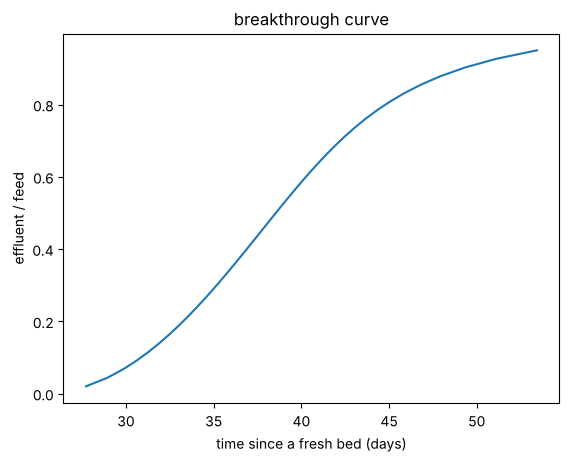

In [9]:
p = dw.GACParams()
feed = make_stream({"H2O": 2433.8, "solute": 0.0548}, T=298.15, P=101325.0)
cs = np.linspace(0.02, 0.95, 40)
ts = []
for c in cs:
    i = dw.GACAdsorber(dw.GACParams(conc_ratio_replace=float(c)))(feed)[2]
    ts.append(float(i["operational_time"]) / 86400)
plt.plot(ts, cs); plt.xlabel("time since a fresh bed (days)"); plt.ylabel("effluent / feed"); plt.title("breakthrough curve")
for ebct in (300.0, 600.0, 1200.0):
    i = dw.GACAdsorber(dw.GACParams(ebct=ebct, velocity_sup=6.0 / ebct))(feed)[2]
    print(f"EBCT {ebct:5.0f} s: bed life {float(i['operational_time']) / 86400:5.1f} d, carbon use {float(i['gac_usage_rate']) * 86400:6.0f} kg/d, "
          f"removal {float(i['removal_fraction']):.3f}, constant pattern valid: {bool(i['constant_pattern'])}")

**Check.** Against WaterTAP's GAC example on four cases (`benchmarks/watertap/gac.py`), live:

In [10]:
ref = json.loads((BENCH / "watertap" / "gac_reference.json").read_text())
from difflow_water.chemistry.seawater import MW_WATER
worst = 0.0
for name, c in ref["cases"].items():
    i, o = c["inputs"], c["outputs"]
    f = make_stream({"H2O": i["flow_mass_H2O"] / MW_WATER, "solute": i["flow_mass_solute"] / 0.08}, T=i["T"], P=i["P"])
    q = dw.GACAdsorber(dw.GACParams(mw_target=0.08, velocity_sup=o["velocity_sup"],
                                    **{k: i[k] for k in ("freund_k", "freund_ninv", "kf", "ds", "particle_dens_app",
                                                         "particle_dia", "ebct", "bed_voidage", "conc_ratio_replace",
                                                         "a0", "a1", "b0", "b1", "b2", "b3", "b4")}))(f)[2]
    rel = max(abs(float(q[k]) / o[k] - 1) for k in ("operational_time", "bed_volumes_treated", "gac_usage_rate", "conc_ratio_avg"))
    worst = max(worst, rel)
    print(f"{name:20s} bed life {o['operational_time'] / 86400:6.1f} d (WaterTAP) {float(q['operational_time']) / 86400:6.1f} d (difflow)")
print(f"largest relative difference {worst:.1e}")

example              bed life   38.5 d (WaterTAP)   38.5 d (difflow)
long_ebct            bed life   58.2 d (WaterTAP)   58.2 d (difflow)
replace_at_0.2       bed life   33.3 d (WaterTAP)   33.3 d (difflow)
freundlich_ninv_0.6  bed life  295.6 d (WaterTAP)  295.6 d (difflow)
largest relative difference 2.0e-14


Note that WaterTAP's own example (EBCT 600 s) is outside the constant-pattern regime the model assumes (`EBCT < EBCT_min`, `constant_pattern` False): the bed is too short for a constant-pattern front, and the throughput regression is extrapolated. The comparison still checks the implementation (the same explicit equations in two codes), not the model: Hand et al. (1984), the source of the regression constants, could not be read, and no published column test was reproduced. The constants (`a0, a1, b0..b4`) depend on the Biot number and `1/n`; the defaults are WaterTAP's example values whatever those are.

## Summary

| Unit | What stands behind it |
|---|---|
| `Sedimentation` | removal law reproduced by particle tracking at every depth; Stokes range reported; no published data |
| `Filtration` | removal law reproduced slice by slice; Yao's efficiency as Messina et al. state it; no published data |
| `Disinfection` | EPA SWTR CT table for *Giardia* (5 and 15 C, pH 7): Chick-Watson fits it within about 3 %; at the table's CT the fitted law gives 2.95-3.09 logs and the unit (200 tanks) 0.05 log less |
| `GACAdsorber` | WaterTAP within 2e-14 (its example is outside the constant-pattern regime); no published column data |